# 3.04 — HistGradientBoostingRegressor | MiBici — Fase 2

**Responsable:** José Emmanuel Vázquez Galán · **Equipo 04** · **Asignatura:** TC5044.10 — Operaciones de aprendizaje automático.

**Objetivo:** justificar, ajustar y evaluar un modelo global `HistGradientBoostingRegressor` para predecir salidas de bicicletas por estación y hora en D+1, con el contrato común del equipo, seguimiento de experimentos en MLflow y evidencia reproducible. Se distinguen explícitamente **exploración muestral**, **validación oficial completa** y **ventanas de estabilidad**. La selección global del equipo, la prueba final y el Model Registry permanecen pendientes de integración.

> **Estado:** experimentación individual completada; resultados de las ventanas verificados en los CSV adjuntos. Las corridas oficiales se ejecutaron con cambios locales no confirmados (`git_dirty=true`), situación que se declara y debe resolverse al publicar la contribución.

## 1. Contrato predictivo y control de alcance

- Dataset: `processed_v1` (`station_hour_v1.parquet`), unidad estación × hora.
- Target: `departures`; predictores: los siete definidos en `mibici.config.FEATURES`.
- Entrenamiento: enero 2022–mayo 2026; validación: junio–julio 2026; prueba: agosto–septiembre 2026, **reservada para integración final**.
- Métricas oficiales: WAPE (principal) y MAE (secundaria), calculadas con `mibici.modeling.metrics.evaluate`.
- Baseline: `make_model("baseline")`, sobre las **mismas filas** de evaluación.
- Comparación adicional por cohortes y ventanas temporales; no confundir muestra exploratoria con resultado oficial.

La disponibilidad temporal de las variables y las reglas retrospectivas de `processed_v1` deben revisarse antes de interpretar la evaluación como una simulación operacional estrictamente causal.

In [18]:
import os
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

from mibici.config import FEATURES, PROJ_ROOT, RANDOM_STATE, STATION_HOUR_PATH, TARGET
from mibici.modeling.metrics import evaluate
from mibici.modeling.models import make_model
from mibici.modeling.splits import train_eval_masks
from mibici.modeling.train import load_modeling_table

os.chdir(PROJ_ROOT)
assert (PROJ_ROOT / "pyproject.toml").exists(), (
    f"Missing project file: {PROJ_ROOT / 'pyproject.toml'}"
)
assert STATION_HOUR_PATH.exists(), f"Missing dataset: {STATION_HOUR_PATH}"
print(
    {
        "python": platform.python_version(),
        "sklearn": sklearn.__version__,
        "dataset": str(STATION_HOUR_PATH),
    }
)

{'python': '3.12.15', 'sklearn': '1.9.1', 'dataset': '/home/jevg/MiBici/data/processed/station_hour_v1.parquet'}


## 2. Diseño experimental y presupuesto computacional

Se utiliza una muestra estratificada por mes y una semilla fija para limitar el costo computacional. **No es una muestra estratificada por estación ni por magnitud del target**, por lo que sus resultados pueden diferir de la validación completa.

El muestreo mensual incluye 53 meses de entrenamiento (954,000 filas) y dos meses de validación (24,000 filas). Se mantienen las particiones temporales oficiales y se evita la validación interna aleatoria de HGB (`early_stopping=False`).

In [ ]:
# Adjustable local exploration budget; never affects the shared training code.
TRAIN_SAMPLE_PER_MONTH = 18_000
VALIDATION_SAMPLE_PER_MONTH = 12_000
USE_FULL_VALIDATION = False
EXPERIMENTS = [
    {"loss": "poisson", "learning_rate": 0.10, "max_iter": 120, "max_leaf_nodes": 15},
    {"loss": "absolute_error", "learning_rate": 0.10, "max_iter": 120, "max_leaf_nodes": 15},
    {"loss": "squared_error", "learning_rate": 0.10, "max_iter": 120, "max_leaf_nodes": 15},
]


def sample_months(df, mask, per_month, seed):
    """Sample rows within each month using stable positional indices."""
    subset = df.loc[mask]
    months = subset["hour_start"].dt.to_period("M")
    rng = np.random.default_rng(seed)
    positions = []
    for idx in subset.groupby(months, sort=True).indices.values():
        positions.extend(rng.choice(idx, size=min(len(idx), per_month), replace=False))
    return subset.iloc[np.sort(np.asarray(positions, dtype=np.int64))]

In [20]:
start = time.perf_counter()
data = load_modeling_table()
train_mask, val_mask = train_eval_masks(data, "validation")
train_df = sample_months(data, train_mask, TRAIN_SAMPLE_PER_MONTH, RANDOM_STATE)
val_df = (
    data.loc[val_mask]
    if USE_FULL_VALIDATION
    else sample_months(data, val_mask, VALIDATION_SAMPLE_PER_MONTH, RANDOM_STATE)
)
assert train_df["hour_start"].max() < val_df["hour_start"].min()
assert set(FEATURES).issubset(data.columns)
assert train_df[TARGET].ge(0).all() and val_df[TARGET].ge(0).all()
print(
    {
        "all_rows": len(data),
        "train_sample": len(train_df),
        "validation_rows": len(val_df),
        "load_seconds": round(time.perf_counter() - start, 1),
    }
)

{'all_rows': 11949160, 'train_sample': 954000, 'validation_rows': 24000, 'load_seconds': 26.4}


## 3. Referencia común y distribución del objetivo

La métrica WAPE divide el error absoluto total entre el volumen observado de salidas. En el mismo conjunto de evaluación, WAPE y MAE ordenan los modelos de manera equivalente; no deben interpretarse como métricas independientes de selección.

La alta frecuencia de ceros y la asimetría de `departures` motivan contrastar funciones de pérdida. El baseline no requiere entrenamiento de parámetros sobre la variable objetivo futura.

In [21]:
baseline = make_model("baseline")
baseline.fit(train_df, train_df[TARGET])
base_scores = evaluate(val_df, baseline.predict(val_df))
display(base_scores)
display(val_df[TARGET].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).to_frame("departures"))
print("Zero target share:", round(val_df[TARGET].eq(0).mean(), 4))

,rows,departures,mae,wape
segment,,,,
all,24000,32949,0.961565,0.700402
established_stations,21107,31492,1.021428,0.684596
new_station_cohort,2893,1457,0.524807,1.042049


,departures
count,24000.000000
mean,1.372875
std,2.395794
min,0.000000
50%,1.000000
90%,4.000000
95%,6.000000
99%,11.000000
max,85.000000


Zero target share: 0.4892


## 4. Comparación exploratoria de funciones de pérdida

Se mantienen fijos `learning_rate=0.10`, `max_iter=120` y `max_leaf_nodes=15` para aislar el efecto de la pérdida. Las configuraciones **no representan todavía un ajuste exhaustivo de hiperparámetros**. Se utiliza el pipeline común `make_model("hgb")` con parámetros anidados `model__regressor__*`.

In [22]:
results = []
for cfg in EXPERIMENTS:
    model = make_model("hgb").set_params(
        **{"model__regressor__" + k: v for k, v in cfg.items()},
        model__regressor__early_stopping=False,
    )
    tic = time.perf_counter()
    model.fit(train_df, train_df[TARGET])
    predictions = model.predict(val_df)
    scores = evaluate(val_df, predictions)
    results.append(
        {
            **cfg,
            "train_rows": len(train_df),
            "validation_rows": len(val_df),
            "wape": float(scores.loc["all", "wape"]),
            "mae": float(scores.loc["all", "mae"]),
            "baseline_wape": float(base_scores.loc["all", "wape"]),
            "fit_seconds": round(time.perf_counter() - tic, 1),
            "overprediction_share": float(np.mean(predictions > val_df[TARGET].to_numpy())),
        }
    )
    print(cfg["loss"], "WAPE", round(results[-1]["wape"], 4))
results_df = pd.DataFrame(results).sort_values("wape").reset_index(drop=True)
display(results_df)

poisson WAPE 0.7176
absolute_error WAPE 0.6615
squared_error WAPE 0.7164


,loss,learning_rate,max_iter,max_leaf_nodes,train_rows,validation_rows,wape,mae,baseline_wape,fit_seconds,overprediction_share
0,absolute_error,0.1,120,15,954000,24000,0.661537,0.908207,0.700402,7.9,0.585292
1,squared_error,0.1,120,15,954000,24000,0.716371,0.983488,0.700402,2.7,0.656792
2,poisson,0.1,120,15,954000,24000,0.717620,0.985202,0.700402,5.1,0.655875


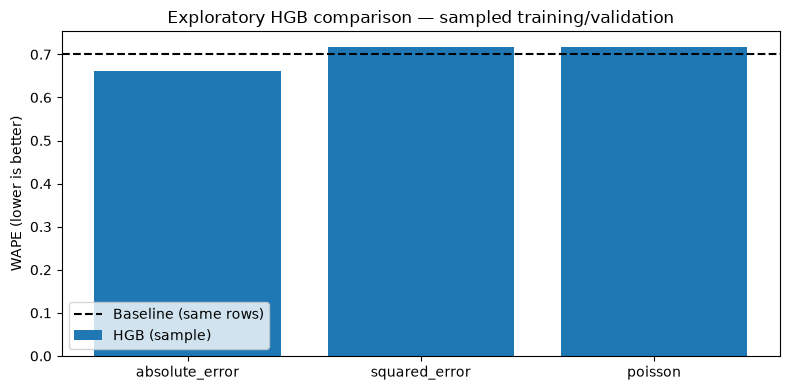

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(results_df["loss"], results_df["wape"], label="HGB (sample)")
ax.axhline(
    float(base_scores.loc["all", "wape"]),
    linestyle="--",
    color="black",
    label="Baseline (same rows)",
)
ax.set(
    ylabel="WAPE (lower is better)",
    title="Exploratory HGB comparison — sampled training/validation",
)
ax.legend()
plt.tight_layout()
plt.show()

### Interpretación de resultados preliminares

En la muestra local, `absolute_error` alcanzó **WAPE = 0.661537** y **MAE = 0.908207**, frente a **WAPE = 0.700402** y **MAE = 0.961565** del baseline. La diferencia de WAPE es **−0.038865**, equivalente a una reducción relativa del **5.55 %**. En contraste, `squared_error` (0.716371) y `poisson` (0.717620) no superaron al baseline.

La proporción de predicciones superiores al valor observado fue 58.53 % con `absolute_error`, frente a aproximadamente 65.6 % con las otras pérdidas. Este indicador es descriptivo y no sustituye una evaluación de calibración ni un análisis de errores por segmento.

**Limitación central:** se trata de resultados obtenidos con entrenamiento y validación muestreados. No deben presentarse como el rendimiento oficial del modelo sobre todo `processed_v1`.

## 5. Análisis por cohortes y diagnóstico de sesgo

El baseline preliminar muestra diferencias entre estaciones establecidas (WAPE ≈ 0.6846) y la cohorte nueva (WAPE ≈ 1.0420). Para HGB se requiere calcular los mismos segmentos sobre las mismas filas, sin utilizar las columnas de segmentación como predictores. La siguiente celda vuelve a ajustar **solo la mejor configuración exploratoria** para obtener los diagnósticos; es opcional y añade un entrenamiento corto.

In [24]:
# Optional diagnostic: one extra fit on the exploratory sample only.
RUN_SEGMENT_DIAGNOSTIC = False

if RUN_SEGMENT_DIAGNOSTIC:
    candidate = make_model("hgb").set_params(
        model__regressor__loss="absolute_error",
        model__regressor__learning_rate=0.10,
        model__regressor__max_iter=120,
        model__regressor__max_leaf_nodes=15,
        model__regressor__early_stopping=False,
    )
    candidate.fit(train_df, train_df[TARGET])
    y_hat = candidate.predict(val_df)
    segment_scores = evaluate(val_df, y_hat)
    comparison = segment_scores[["rows", "mae", "wape"]].join(
        base_scores[["mae", "wape"]].rename(
            columns={"mae": "baseline_mae", "wape": "baseline_wape"}
        )
    )
    display(comparison)
    print(
        {
            "overprediction_share": float(np.mean(y_hat > val_df[TARGET].to_numpy())),
            "mean_prediction": float(np.mean(y_hat)),
            "mean_observed": float(val_df[TARGET].mean()),
            "negative_predictions": int(np.sum(y_hat < 0)),
        }
    )
else:
    print("Segment diagnostic skipped; set RUN_SEGMENT_DIAGNOSTIC=True to execute.")

Segment diagnostic skipped; set RUN_SEGMENT_DIAGNOSTIC=True to execute.


## 6. Ajuste de hiperparámetros y selección oficial

El análisis exploratorio comparó `poisson`, `squared_error` y `absolute_error` sobre la misma muestra. En esa fase, la pérdida absoluta obtuvo el menor WAPE. Posteriormente se ejecutó el **grid oficial sobre la partición completa de validación**, conservando `loss="absolute_error"`, `max_iter=120`, `early_stopping=False`, `random_state=0` y el pipeline común. Se ajustaron `learning_rate ∈ {0.05, 0.10}` y `max_leaf_nodes ∈ {15, 31}`.

| Corrida MLflow | learning_rate | max_leaf_nodes | WAPE HGB | MAE HGB | WAPE baseline | MAE baseline | Ajuste (s) |
|---|---:|---:|---:|---:|---:|---:|---:|
| `hgb-validation-01` | 0.05 | 15 | 0.662 | 0.919 | 0.696 | 0.967 | 99.9 |
| `hgb-validation-02` | 0.05 | 31 | 0.659 | 0.915 | 0.696 | 0.967 | 103.7 |
| `hgb-validation-03` | 0.10 | 15 | 0.662 | 0.919 | 0.696 | 0.967 | 89.5 |
| **`hgb-validation-04`** | **0.10** | **31** | **0.657** | **0.913** | **0.696** | **0.967** | **95.8** |

*Los valores de la tabla anterior están redondeados a tres decimales, tal como los presentó la terminal. No deben interpretarse como precisión de seis decimales.*

### Configuración histórica y configuración seleccionada

La búsqueda oficial de hiperparámetros se realizó mediante una cuadrícula de cuatro combinaciones, manteniendo constantes la función de pérdida absoluta, el número máximo de iteraciones, la desactivación de la detención temprana y la semilla aleatoria.

```python
# Historical tuning grid used during validation
{
    "model__regressor__learning_rate": [0.05, 0.10],
    "model__regressor__max_leaf_nodes": [15, 31],
}
```

El experimento `hgb-validation-04` obtuvo el menor WAPE de validación. Por este motivo, la versión final del estimador conserva `learning_rate=0.10` y `max_leaf_nodes=31`, mientras que `param_grid={}` evita repetir innecesariamente la búsqueda durante las ejecuciones de integración.

Esta decisión separa la **trazabilidad del ajuste histórico** de la **reproducción de la configuración seleccionada**. Los resultados originales permanecen identificados mediante sus respectivas corridas de MLflow. Para repetir íntegramente el ajuste, debe restaurarse la cuadrícula histórica exclusivamente en el bloque HGB de `models.py`, sin modificar los modelos de otros integrantes.

La selección se efectuó utilizando únicamente el conjunto de validación. El conjunto de prueba permanece reservado para la evaluación final coordinada por el equipo.

## 7. Reproducibilidad y trazabilidad

**Fuente de datos:** `data/processed/station_hour_v1.parquet` (`processed_v1`), con features históricos calculados por el módulo común. **Particiones:** entrenamiento 2022-01-01 a 2026-05-31; validación 2026-06-01 a 2026-07-31; test 2026-08-01 a 2026-09-30. El entrenamiento de julio amplía su historia hasta junio, según el contrato. **Métricas:** WAPE principal y MAE secundaria, por segmentos.

**Código compartido:** `mibici/config.py`, `features.py`, `modeling/splits.py`, `pipeline.py`, `metrics.py` y `train.py` permanecen sin modificaciones por parte del responsable HGB. El bloque propio se encuentra en `mibici/modeling/models.py`; el notebook importa las funciones comunes y conserva la exploración muestral como evidencia de selección de pérdida.

**Ejecución en WSL (desde la raíz de MiBici):**

```bash
conda activate mibici
make test && make lint
# En otra terminal: make mlflow
make train MODEL=hgb MODE=validation
make train MODEL=hgb MODE=window_june
make train MODEL=hgb MODE=window_july
```

**Reproducción del modelo seleccionado:** la versión final de `mibici/modeling/models.py` incorpora directamente los hiperparámetros de `hgb-validation-04` y define `param_grid={}`. Por tanto, `make_model("hgb")` y `make train MODEL=hgb MODE=validation` utilizan la misma configuración sin requerir modificaciones manuales. Las ejecuciones `window_june` y `window_july` reutilizan el estimador y aplican las particiones temporales definidas en el contrato común.

**Reproducción del ajuste histórico:** la cuadrícula original de cuatro combinaciones se conserva en la sección 6. Para repetirla, debe configurarse temporalmente ese grid en el bloque HGB, ejecutar la validación y posteriormente restaurar la configuración seleccionada. Esta operación no requiere modificar `config.py`, el pipeline compartido ni los modelos de los demás integrantes.

**Trazabilidad:** los identificadores de MLflow permiten localizar las corridas originales en el servidor local donde se generaron. Como los experimentos se ejecutaron antes del commit, presentan `git_dirty=true`; por ello, los identificadores y las métricas documentan las ejecuciones realizadas, pero no equivalen por sí solos a una versión de código confirmada en Git. Posteriormente, el equipo confirmó la reproducción independiente de HGB desde el código integrado mediante el PR #11 en su infraestructura DGX, obteniendo métricas coincidentes al nivel de precisión reportado.

**Estado de versionado al producir los resultados:** rama `feat/f2-hgb-jevg`, base `de0a895`; las ejecuciones de MLflow muestran `git_dirty=true` porque aún no se había realizado commit. Los identificadores de MLflow corresponden a un servidor local (`http://127.0.0.1:5000`) y no constituyen enlaces públicos. Tras publicar el PR, el equipo puede repetir la corrida elegida desde un árbol limpio para obtener trazabilidad definitiva. No subir `mlflow/`, bases de datos locales, modelos binarios ni logs voluminosos.

**Pruebas:** `make test`: 95 aprobadas; `make lint`: Ruff sin errores, según la salida compartida. **Pendiente global:** comparar con los otros modelos, evaluar test una sola vez y registrar el candidato ganador en MLflow Model Registry con versión, hiperparámetros y métricas.

## 8. Evidencia de MLflow y estabilidad temporal

| Evaluación | Corrida | WAPE HGB | WAPE baseline | MAE HGB | MAE baseline | Ajuste (s) | Filas evaluadas |
|---|---|---:|---:|---:|---:|---:|---:|
| Validación completa | `hgb-validation-04` | 0.657 | 0.696 | 0.913 | 0.967 | 95.8 | 511,960 |
| Junio | `hgb-window_june-01` | **0.685814** | 0.722694 | 0.967049 | 1.019053 | 98.6 | 240,200 |
| Julio | `hgb-window_july-01` | **0.632255** | 0.672383 | 0.866031 | 0.920995 | 99.4 | 271,760 |

Las cifras completas de junio y julio provienen de `scores_by_segment.csv` de las corridas correspondientes. Los valores de validación completa se muestran redondeados según el resumen de terminal; para recuperar su precisión íntegra debe consultarse el artefacto original de MLflow.

**IDs de corrida (servidor local):**

- Validación 01: `bc65efb678e54fc18bd94b35e4abaa01`; validación 02: `4632fd94d1dd42f5b89fdcf113297d13`; validación 03: `49613e5be36544d6b9f0970d431a265e`; validación 04: `75ef0a746c004f2eb44be5c25338948c`.
- Junio: `8eb2e005677d4c88815746049724ce9d`.
- Julio: `36066685d2da46b6ac2139fbd24268bd`.

**Interpretación:** la configuración seleccionada supera al baseline en ambas ventanas. No obstante, junio y julio presentan diferentes condiciones de demanda y distintos conjuntos de entrenamiento, por lo que la diferencia entre sus WAPE no debe atribuirse exclusivamente al algoritmo.

### 8.1. Análisis por segmento

| Ventana | Segmento | WAPE HGB | WAPE baseline | Reducción relativa |
|---|---|---:|---:|---:|
| Junio | Establecidas | 0.674157 | 0.708077 | 4.79 % |
| Junio | Cohorte nueva 2026 | 1.027008 | 1.150556 | 10.74 % |
| Julio | Establecidas | 0.615387 | 0.649943 | 5.32 % |
| Julio | Cohorte nueva 2026 | 0.936324 | 1.076870 | 13.05 % |

La mejora también se observa en las estaciones nuevas, pero su error relativo sigue siendo elevado. Este resultado justifica monitorear por separado estaciones de reciente incorporación y no utilizar exclusivamente la métrica agregada para decisiones operativas.

### 8.2. Visualización reproducible

La siguiente celda construye tablas y figuras **sin volver a entrenar**. Sus valores de junio y julio son una transcripción verificable de los artefactos CSV entregados. Cuando estos artefactos estén disponibles en el repositorio, pueden sustituirse por una lectura directa de las exportaciones de MLflow.

,window,segment,hgb_wape,baseline_wape,relative_wape_reduction_pct
0,Junio,all,0.685814,0.722694,5.103159
1,Junio,established_stations,0.674157,0.708077,4.790350
2,Junio,new_station_cohort,1.027008,1.150556,10.738066
3,Julio,all,0.632255,0.672383,5.967947
4,Julio,established_stations,0.615387,0.649943,5.316873
5,Julio,new_station_cohort,0.936324,1.076870,13.051335


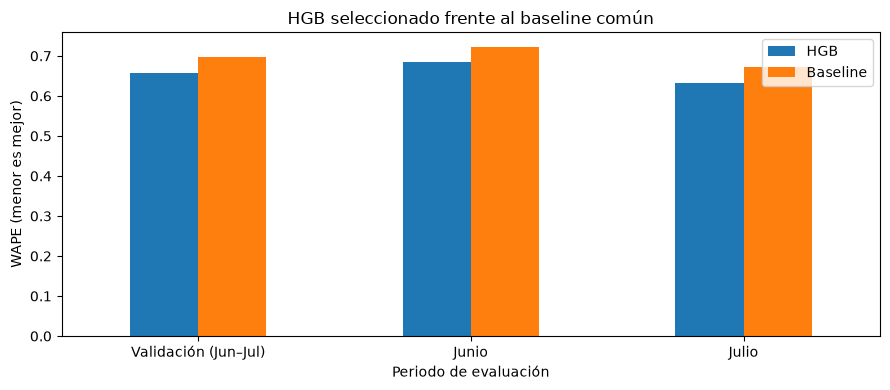

In [25]:
# Read-only presentation of verified MLflow score artifacts (no model fitting).
# Validation values are rounded to the precision available in the terminal output.
import matplotlib.pyplot as plt
import pandas as pd

window_scores = pd.DataFrame(
    [
        {
            "window": "Junio",
            "segment": "all",
            "hgb_wape": 0.685813817027766,
            "baseline_wape": 0.7226940420189407,
        },
        {
            "window": "Junio",
            "segment": "established_stations",
            "hgb_wape": 0.6741573337704561,
            "baseline_wape": 0.7080766825570817,
        },
        {
            "window": "Junio",
            "segment": "new_station_cohort",
            "hgb_wape": 1.0270084267413115,
            "baseline_wape": 1.1505558719155293,
        },
        {
            "window": "Julio",
            "segment": "all",
            "hgb_wape": 0.6322551502161594,
            "baseline_wape": 0.6723825878642696,
        },
        {
            "window": "Julio",
            "segment": "established_stations",
            "hgb_wape": 0.6153867633246156,
            "baseline_wape": 0.6499434328197392,
        },
        {
            "window": "Julio",
            "segment": "new_station_cohort",
            "hgb_wape": 0.9363240974247404,
            "baseline_wape": 1.0768700053339795,
        },
    ]
)
window_scores["relative_wape_reduction_pct"] = (
    100
    * (window_scores["baseline_wape"] - window_scores["hgb_wape"])
    / window_scores["baseline_wape"]
)
display(window_scores)

comparison = pd.DataFrame(
    [
        {"evaluation": "Validación (Jun–Jul)", "hgb_wape": 0.657, "baseline_wape": 0.696},
        {
            "evaluation": "Junio",
            "hgb_wape": 0.685813817027766,
            "baseline_wape": 0.7226940420189407,
        },
        {
            "evaluation": "Julio",
            "hgb_wape": 0.6322551502161594,
            "baseline_wape": 0.6723825878642696,
        },
    ]
)
ax = comparison.set_index("evaluation")[["hgb_wape", "baseline_wape"]].plot(
    kind="bar", figsize=(9, 4), rot=0
)
ax.set_ylabel("WAPE (menor es mejor)")
ax.set_xlabel("Periodo de evaluación")
ax.set_title("HGB seleccionado frente al baseline común")
ax.legend(["HGB", "Baseline"])
plt.tight_layout()
plt.show()

,run,learning_rate,max_leaf_nodes,wape,mae,fit_seconds
0,hgb-validation-01,0.05,15,0.662,0.919,99.9
1,hgb-validation-02,0.05,31,0.659,0.915,103.7
2,hgb-validation-03,0.10,15,0.662,0.919,89.5
3,hgb-validation-04,0.10,31,0.657,0.913,95.8


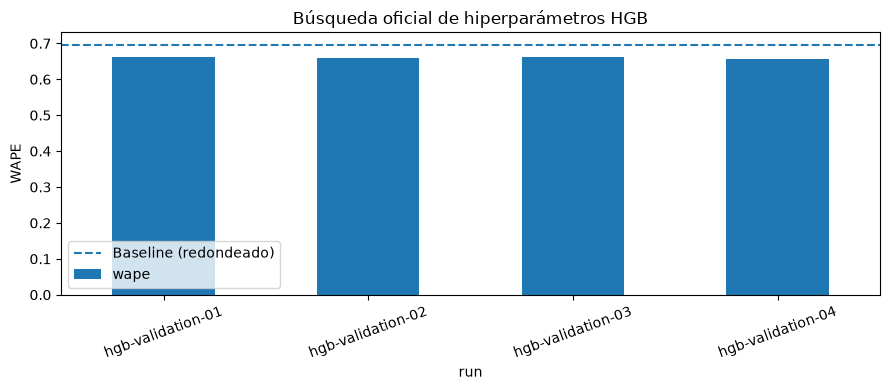

In [26]:
# Official validation grid: values rounded as printed by the training command.
validation_grid = pd.DataFrame(
    [
        {
            "run": "hgb-validation-01",
            "learning_rate": 0.05,
            "max_leaf_nodes": 15,
            "wape": 0.662,
            "mae": 0.919,
            "fit_seconds": 99.9,
        },
        {
            "run": "hgb-validation-02",
            "learning_rate": 0.05,
            "max_leaf_nodes": 31,
            "wape": 0.659,
            "mae": 0.915,
            "fit_seconds": 103.7,
        },
        {
            "run": "hgb-validation-03",
            "learning_rate": 0.10,
            "max_leaf_nodes": 15,
            "wape": 0.662,
            "mae": 0.919,
            "fit_seconds": 89.5,
        },
        {
            "run": "hgb-validation-04",
            "learning_rate": 0.10,
            "max_leaf_nodes": 31,
            "wape": 0.657,
            "mae": 0.913,
            "fit_seconds": 95.8,
        },
    ]
)
display(validation_grid)
ax = validation_grid.plot.bar(x="run", y="wape", legend=False, figsize=(9, 4), rot=20)
ax.axhline(0.696, linestyle="--", label="Baseline (redondeado)")
ax.set_ylabel("WAPE")
ax.set_title("Búsqueda oficial de hiperparámetros HGB")
ax.legend()
plt.tight_layout()
plt.show()

### 8.3. Evidencia visual de MLflow

Como complemento a las métricas registradas y los identificadores de ejecución, se incorporaron capturas verificables de la interfaz de MLflow Tracking en el directorio `reports/evidence/f2_hgb/`.

| Archivo | Contenido |
|---|---|
| `01_validation_runs.png` | Comparación de las cuatro configuraciones de validación y las ventanas temporales |
| `02_hgb_validation_best.png` | Métricas de la configuración seleccionada, `hgb-validation-04` |
| `03_hgb_window_june.png` | Evaluación de estabilidad temporal correspondiente a junio |
| `04_hgb_window_july.png` | Evaluación de estabilidad temporal correspondiente a julio |

Las capturas permiten consultar visualmente las métricas globales y por cohorte, así como los identificadores de ejecución y las referencias de versionado. Constituyen evidencia complementaria y no reemplazan los registros originales de MLflow ni la reproducción independiente efectuada por el equipo.

## 9. Interpretación, conclusiones y limitaciones

Durante esta fase comparé tres funciones de pérdida y observé que `absolute_error` produjo mejores resultados que `poisson` y `squared_error` en la muestra exploratoria. A partir de esa evidencia, ejecuté cuatro combinaciones de hiperparámetros con la validación oficial y seleccioné `learning_rate=0.10` y `max_leaf_nodes=31`, conservando `max_iter=120` y `early_stopping=False`. La configuración seleccionada obtuvo WAPE aproximado de **0.657**, frente a **0.696** del baseline común.

Posteriormente comprobé su estabilidad con las ventanas de junio y julio, en las cuales el WAPE disminuyó de **0.722694 a 0.685814** y de **0.672383 a 0.632255**, respectivamente. Esta consistencia respalda su incorporación como **candidato** a la comparación final del equipo. La mejora también se presenta en estaciones establecidas y nuevas, aunque el WAPE de la cohorte nueva continúa siendo considerablemente superior y representa una oportunidad de mejora.

***No obstante, la mejora en WAPE debe interpretarse junto con el sesgo agregado de subestimación identificado posteriormente, particularmente por sus implicaciones para el rebalanceo de bicicletas.***

Considero especialmente relevante haber reutilizado el contrato común del equipo, porque esto permitió comparar el desempeño sin introducir cambios en el objetivo predictivo, las variables, los cortes temporales ni las métricas. Los experimentos se registraron en MLflow y se verificó el funcionamiento de la base de código mediante 95 pruebas unitarias y las comprobaciones de Ruff. Aunque las ejecuciones originales se realizaron con cambios locales no confirmados (`git_dirty=true`), posteriormente el equipo reprodujo la configuración publicada en el PR #11 utilizando la infraestructura DGX, obteniendo resultados coincidentes al nivel de precisión reportado: WAPE de 0.657 en validación, 0.686 en junio y 0.632 en julio. Esta verificación independiente fortalece la reproducibilidad del candidato, sin sustituir la evaluación final sobre el conjunto de prueba reservado.

El análisis todavía no constituye una evaluación final fuera de muestra: el test agosto–septiembre permanece reservado. Tampoco se ha demostrado el registro del modelo en Model Registry, actividad que corresponde a la integración grupal. Adicionalmente, el histórico de estaciones y las características retrospectivas deben revisarse al diseñar una operación real con datos disponibles al corte D+1; las mejoras observadas no equivalen por sí mismas a una garantía de despliegue productivo.

### Limitación adicional: subestimación del volumen de demanda

Aunque HGB obtuvo mejores resultados de WAPE que el baseline común en validación y en ambas ventanas de estabilidad, la evaluación complementaria realizada por el equipo identificó un **sesgo agregado de subestimación** que debe considerarse antes de seleccionar el modelo para uso operativo.

En particular, HGB pronosticó aproximadamente **21 % menos salidas que las observadas** en el conjunto analizado, y la subestimación alcanzó aproximadamente **40 % en las estaciones nuevas**, frente a una diferencia cercana al **2 % para el baseline**. Estas cifras corresponden al diagnóstico adicional compartido por el equipo y no deben confundirse con los valores de WAPE.

Desde una perspectiva estadística, la función de pérdida `absolute_error` favorece la estimación de la mediana condicional de la variable objetivo. En una distribución de demanda asimétrica, con numerosas observaciones de cero salidas y episodios de demanda elevada, este comportamiento puede reducir el error absoluto sin conservar necesariamente el volumen agregado observado.

Para el caso de MiBici, esta diferencia es relevante porque las predicciones podrían utilizarse para anticipar necesidades de disponibilidad y rebalanceo de bicicletas. Una subestimación sistemática podría conducir a decisiones de asignación insuficiente, especialmente en estaciones recientemente incorporadas.

Por ello, considero que **HGB debe mantenerse como candidato a la comparación final, pero no seleccionarse exclusivamente por su WAPE**. Recomiendo que el equipo evalúe conjuntamente el error absoluto, el sesgo agregado de volumen, el comportamiento por cohortes y las consecuencias operativas de la subestimación. Cualquier ajuste de calibración posterior deberá validarse sin utilizar el conjunto de prueba para seleccionar parámetros.

El diagnóstico de sesgo agregado fue comunicado por el equipo durante la revisión posterior al PR #11; las cifras se presentan como aproximaciones y no como métricas calculadas originalmente en este notebook.

### Interacción entre roles

La integración se apoyó en el contrato de modelado y la infraestructura compartida de Leonardo Santos García; la experimentación HGB estuvo a mi cargo; las alternativas Poisson y Random Forest son responsabilidad de José Eduardo De Moraes López y Erik Román Cortez, respectivamente. La comparación final, la decisión de selección y el registro del modelo requieren revisión conjunta. Los resultados de Random Forest compartidos por Erik motivaron la exploración de pérdidas resistentes a la asimetría del objetivo, sin modificar los experimentos de los demás compañeros.

## 10. Declaración de uso de herramientas de inteligencia artificial

Durante el desarrollo de esta actividad utilicé **ChatGPT (OpenAI, modelo GPT-6)**, **Microsoft 365 Copilot (Microsoft, basado en GPT-5)** y **GitHub Copilot (modelo GPT 5.6 Luna)** como herramientas de apoyo para la estructuración del notebook, la documentación técnica, la revisión metodológica y la depuración de errores de ejecución. Las versiones indicadas corresponden a los modelos que verifiqué durante su utilización.

Estas herramientas contribuyeron a identificar oportunidades de mejora en la organización del código, la interpretación de resultados y la presentación de evidencias. Sin embargo, las métricas, los tiempos de entrenamiento y los resultados documentados provienen de ejecuciones locales de Scikit-Learn y MLflow sobre los datos del proyecto MiBici, y no de estimaciones generadas por los asistentes de IA.

La selección de hiperparámetros, la validación de las evidencias, la interpretación de las limitaciones y la responsabilidad académica del trabajo permanecieron bajo mi supervisión. Asimismo, se respetó el contrato de modelado establecido por el equipo y se evitó modificar los componentes compartidos fuera del bloque correspondiente a HGB.

**Referencias técnicas del proyecto:** `notebooks/3.01-lsg-modeling-contract.ipynb`, `mibici/config.py`, `mibici/modeling/models.py`, `mibici/modeling/train.py` y los artefactos `scores_by_segment.csv` registrados mediante MLflow.